# Primeros modelos: XGBoost y CatBoost — Gemelo Digital de Aruba

En este notebook probamos los dos primeros modelos de Machine Learning para predecir la generación renovable de la isla. Partimos del dataset que genera `calcular_target.py` y usamos la misma división en entrenamiento y prueba que definimos en el EDA.

El orden es:

1. Carga de los datos y división temporal.
2. Qué variables le damos al modelo.
3. Modelo de referencia: la persistencia.
4. XGBoost.
5. CatBoost.
6. Comparativa a 1 hora.
7. Qué variables pesan más.
8. Predicción a 24 horas.
9. Conclusiones y siguientes pasos.

**¿Por qué estos dos modelos?** Los dos son de *gradient boosting*: construyen muchos árboles de decisión pequeños, uno detrás de otro, y cada árbol corrige los errores de los anteriores. Funcionan muy bien con datos en forma de tabla como los nuestros, captan relaciones no lineales (como la curva de potencia de las turbinas), no necesitan que escalemos las variables y aceptan valores vacíos. La diferencia principal está en cómo construyen los árboles: XGBoost es el más conocido y CatBoost suele dar buenos resultados con poco ajuste de parámetros.

Las figuras, tablas y modelos entrenados se guardan en `resultados/05_modelos/`.

In [1]:
%pip install xgboost catboost scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# El notebook está dentro de modelos/, así que la raíz del repo es la carpeta de arriba
RAIZ = Path("..")
DATASET = RAIZ / "ETL" / "TransformadasYCalculadas" / "dataset_modelo_5min.csv.gz"

SALIDA = RAIZ / "resultados" / "05_modelos"
FIGURAS = SALIDA / "figuras"
TABLAS = SALIDA / "tablas"
MODELOS = SALIDA / "modelos"
for carpeta in (FIGURAS, TABLAS, MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

AZUL = "#2a78d6"
NARANJA = "#eb6834"
VERDE = "#1baf7a"

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIGURAS / f"{nombre}.png", dpi=150)
    plt.show()

## 1. Carga de los datos y división temporal

Cargamos el dataset y quitamos las filas de los huecos (`hay_lectura = 0`). Como explicamos en el EDA, al ser una serie temporal no se puede dividir al azar: entrenamos con el pasado y evaluamos con el futuro.

Además del entrenamiento y la prueba, separamos un trozo del final del entrenamiento como **validación** (mayo y junio de 2026). Lo usamos para que el modelo sepa cuándo dejar de añadir árboles: si el error en validación deja de bajar, paramos. A esto se le llama *early stopping* y sirve para evitar el sobreajuste, es decir, que el modelo se aprenda de memoria el entrenamiento y luego falle con datos nuevos.

| Parte | Fechas | Para qué se usa |
|---|---|---|
| Entrenamiento | 1 sep 2025 – 30 abr 2026 | Aprender |
| Validación | 1 may – 30 jun 2026 | Decidir cuándo parar |
| Prueba | 1 jul – 17 sep 2026 | Evaluar al final, una sola vez |

In [3]:
datos = pd.read_csv(DATASET, index_col="timestamp")
datos.index = pd.to_datetime(datos.index)
datos = datos[datos["hay_lectura"] == 1]

OBJETIVO = "target_P_renovable_t+1h"
INICIO_VALIDACION = "2026-05-01"
INICIO_PRUEBA = "2026-07-01"

def dividir(df, objetivo):
    # Quitamos las filas sin target (las del final y las de justo antes de cada hueco)
    df = df.dropna(subset=[objetivo])
    train = df[df.index < INICIO_VALIDACION]
    val = df[(df.index >= INICIO_VALIDACION) & (df.index < INICIO_PRUEBA)]
    test = df[df.index >= INICIO_PRUEBA]
    return train, val, test

train, val, test = dividir(datos, OBJETIVO)
print("Entrenamiento:", len(train), "filas")
print("Validación:   ", len(val), "filas")
print("Prueba:       ", len(test), "filas")

Entrenamiento: 66936 filas
Validación:    17568 filas
Prueba:        22716 filas


## 2. Qué variables le damos al modelo

Nunca le damos al modelo las columnas de target (`target_P_renovable_t+1h` y `t+24h`) ni la columna de control `hay_lectura`. Eso sí sería hacer trampa, porque son justo lo que queremos predecir.

Con el resto hay una duda que queremos comprobar. En el EDA dijimos que dejaríamos fuera la generación del instante actual (`P_eolica_MW`, `P_solar_MW`, `P_renovable_MW` y `P_renovable_media_1h`) por prudencia. Pensándolo mejor, en el momento de hacer la predicción la generación actual ya se conoce: se calcula con las lecturas de ese mismo instante. Usarla no es fuga de datos, igual que no lo es usar el viento actual. Para salir de dudas probamos los dos conjuntos:

- **Conjunto A:** sin la generación actual, como dijimos en el EDA.
- **Conjunto B:** con la generación actual.

In [4]:
NO_USAR = ["hay_lectura", "target_P_renovable_t+1h", "target_P_renovable_t+24h"]
GENERACION_ACTUAL = ["P_eolica_MW", "P_solar_MW", "P_renovable_MW", "P_renovable_media_1h"]

variables_B = [c for c in datos.columns if c not in NO_USAR]
variables_A = [c for c in variables_B if c not in GENERACION_ACTUAL]

print("Conjunto A:", len(variables_A), "variables")
print("Conjunto B:", len(variables_B), "variables")

Conjunto A: 46 variables
Conjunto B: 50 variables


## 3. Modelo de referencia: la persistencia

Antes de entrenar nada necesitamos una referencia con la que comparar. La más sencilla es la **persistencia**: suponer que dentro de una hora habrá exactamente la misma generación que ahora. No aprende nada, pero como la generación cambia despacio, acierta bastante. Si un modelo de Machine Learning no la mejora, no merece la pena usarlo.

Para evaluar usamos tres medidas:

- **MAE** (error absoluto medio): cuántos MW nos equivocamos de media. Es la más fácil de interpretar.
- **RMSE** (raíz del error cuadrático medio): parecida, pero castiga más los errores grandes.
- **R²**: qué parte de la variación del target explica el modelo. 1 sería perfecto y 0, no explicar nada.

In [5]:
def evaluar(nombre, real, prediccion):
    return {"modelo": nombre,
            "MAE (MW)": mean_absolute_error(real, prediccion),
            "RMSE (MW)": np.sqrt(mean_squared_error(real, prediccion)),
            "R²": r2_score(real, prediccion)}

prediccion_persistencia = test["P_renovable_MW"]
resultados = [evaluar("Persistencia", test[OBJETIVO], prediccion_persistencia)]
pd.DataFrame(resultados).round(3)

,modelo,MAE (MW),RMSE (MW),R²
0,Persistencia,0.919,1.342,0.875


La persistencia se equivoca de media 0,92 MW. Esa es la cifra que tienen que mejorar los modelos.

## 4. XGBoost

Estos son los parámetros que usamos y lo que significa cada uno. No los hemos ajustado todavía: son valores habituales para empezar.

| Parámetro | Valor | Qué hace |
|---|---|---|
| `n_estimators` | 2000 | Número máximo de árboles (el early stopping parará antes) |
| `learning_rate` | 0,05 | Cuánto corrige cada árbol; más bajo es más lento pero más estable |
| `max_depth` | 6 | Profundidad de cada árbol; limita lo complejo que puede ser |
| `subsample` | 0,8 | Cada árbol se entrena con el 80 % de las filas, para no sobreajustar |
| `colsample_bytree` | 0,8 | Y con el 80 % de las variables, por el mismo motivo |
| `early_stopping_rounds` | 100 | Si en 100 árboles seguidos no mejora la validación, para |

In [6]:
def entrenar_xgboost(train, val, variables, objetivo):
    modelo = XGBRegressor(n_estimators=2000, learning_rate=0.05, max_depth=6,
                          subsample=0.8, colsample_bytree=0.8,
                          early_stopping_rounds=100, random_state=0)
    modelo.fit(train[variables], train[objetivo],
               eval_set=[(train[variables], train[objetivo]), (val[variables], val[objetivo])],
               verbose=False)
    return modelo

modelos = {}
for conjunto, variables in [("A", variables_A), ("B", variables_B)]:
    inicio = time.time()
    modelo = entrenar_xgboost(train, val, variables, OBJETIVO)
    prediccion = modelo.predict(test[variables])
    resultados.append(evaluar(f"XGBoost ({conjunto})", test[OBJETIVO], prediccion))
    modelos[f"XGBoost ({conjunto})"] = (modelo, variables, prediccion)
    print(f"XGBoost {conjunto}: {modelo.best_iteration + 1} árboles, {time.time() - inicio:.0f} s")

pd.DataFrame(resultados).round(3)

XGBoost A: 126 árboles, 6 s
XGBoost B: 60 árboles, 4 s


,modelo,MAE (MW),RMSE (MW),R²
0,Persistencia,0.919,1.342,0.875
1,XGBoost (A),0.580,1.039,0.925
2,XGBoost (B),0.620,1.084,0.919


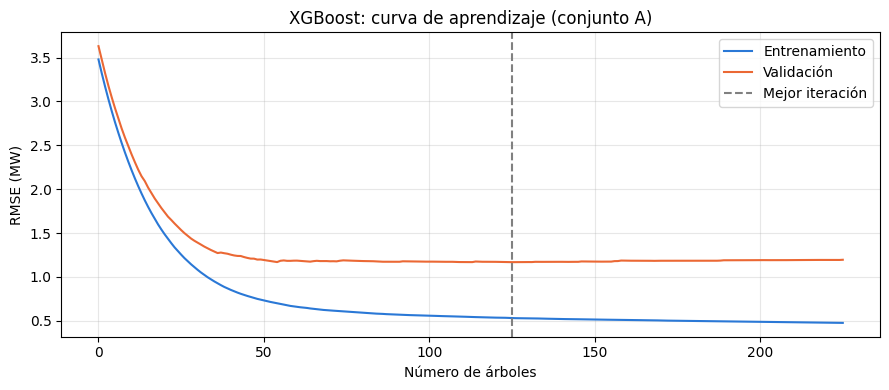

In [7]:
# Curva de aprendizaje: cómo baja el error con cada árbol en entrenamiento y en validación
historial = modelos["XGBoost (A)"][0].evals_result()

fig, eje = plt.subplots(figsize=(9, 4))
eje.plot(historial["validation_0"]["rmse"], color=AZUL, label="Entrenamiento")
eje.plot(historial["validation_1"]["rmse"], color=NARANJA, label="Validación")
eje.axvline(modelos["XGBoost (A)"][0].best_iteration, color="grey", linestyle="--", label="Mejor iteración")
eje.set_xlabel("Número de árboles")
eje.set_ylabel("RMSE (MW)")
eje.set_title("XGBoost: curva de aprendizaje (conjunto A)")
eje.legend()
eje.grid(alpha=0.3)
guardar(fig, "04_xgboost_curva_aprendizaje")

El error en entrenamiento sigue bajando con cada árbol, pero el de validación se estanca pronto, a partir de un centenar de árboles. Si siguiéramos añadiendo árboles, el modelo mejoraría en los datos que ya conoce y empeoraría con los nuevos: eso es el sobreajuste que evita el early stopping. Que pare tan pronto indica que no hay mucho más que aprender de estos datos, algo lógico si tenemos en cuenta que el viento simulado tiene una parte bastante aleatoria.

## 5. CatBoost

CatBoost usa árboles "simétricos", en los que todos los nodos de un mismo nivel hacen la misma pregunta. Eso los hace más sencillos y menos propensos a sobreajustar. Usamos parámetros equivalentes a los de XGBoost para que la comparación sea justa:

| Parámetro | Valor | Qué hace |
|---|---|---|
| `iterations` | 2000 | Número máximo de árboles |
| `learning_rate` | 0,05 | Igual que en XGBoost |
| `depth` | 6 | Profundidad de cada árbol |
| `od_wait` | 100 | Early stopping: para si en 100 árboles no mejora la validación |

In [8]:
def entrenar_catboost(train, val, variables, objetivo):
    modelo = CatBoostRegressor(iterations=2000, learning_rate=0.05, depth=6,
                               od_type="Iter", od_wait=100, random_seed=0, verbose=0)
    modelo.fit(train[variables], train[objetivo],
               eval_set=(val[variables], val[objetivo]), use_best_model=True)
    return modelo

for conjunto, variables in [("A", variables_A), ("B", variables_B)]:
    inicio = time.time()
    modelo = entrenar_catboost(train, val, variables, OBJETIVO)
    prediccion = modelo.predict(test[variables])
    resultados.append(evaluar(f"CatBoost ({conjunto})", test[OBJETIVO], prediccion))
    modelos[f"CatBoost ({conjunto})"] = (modelo, variables, prediccion)
    print(f"CatBoost {conjunto}: {modelo.get_best_iteration() + 1} árboles, {time.time() - inicio:.0f} s")

pd.DataFrame(resultados).round(3)

CatBoost A: 135 árboles, 2 s
CatBoost B: 174 árboles, 3 s


,modelo,MAE (MW),RMSE (MW),R²
0,Persistencia,0.919,1.342,0.875
1,XGBoost (A),0.580,1.039,0.925
2,XGBoost (B),0.620,1.084,0.919
3,CatBoost (A),0.527,0.963,0.936
4,CatBoost (B),0.508,0.942,0.938


## 6. Comparativa a 1 hora

### 6.1 Tabla de resultados

In [9]:
tabla = pd.DataFrame(resultados).set_index("modelo")
mae_persistencia = tabla.loc["Persistencia", "MAE (MW)"]
tabla["mejora sobre la persistencia (%)"] = 100 * (1 - tabla["MAE (MW)"] / mae_persistencia)
tabla = tabla.round(3)
tabla.to_csv(TABLAS / "06_comparativa_1h.csv")
tabla

,MAE (MW),RMSE (MW),R²,mejora sobre la persistencia (%)
modelo,,,,
Persistencia,0.919,1.342,0.875,0.000
XGBoost (A),0.580,1.039,0.925,36.851
XGBoost (B),0.620,1.084,0.919,32.476
CatBoost (A),0.527,0.963,0.936,42.684
CatBoost (B),0.508,0.942,0.938,44.665


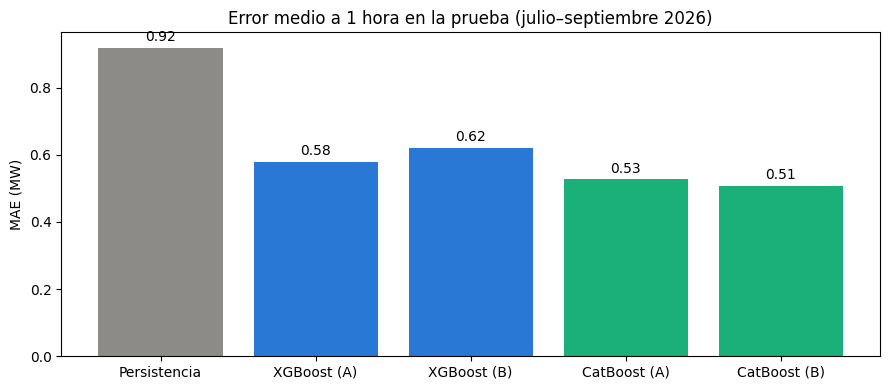

In [10]:
fig, eje = plt.subplots(figsize=(9, 4))
colores = ["#8c8b87"] + [AZUL, AZUL, VERDE, VERDE]
eje.bar(tabla.index, tabla["MAE (MW)"], color=colores)
for x, valor in enumerate(tabla["MAE (MW)"]):
    eje.text(x, valor + 0.02, f"{valor:.2f}", ha="center")
eje.set_ylabel("MAE (MW)")
eje.set_title("Error medio a 1 hora en la prueba (julio–septiembre 2026)")
guardar(fig, "06_comparativa_mae_1h")

Los cuatro modelos mejoran claramente a la persistencia: pasan de casi 0,92 MW de error a entre 0,51 y 0,61 MW, es decir, entre un 34 % y un 45 % menos. CatBoost sale mejor que XGBoost con los dos conjuntos de variables y explica alrededor del 94 % de la variación del target.

Sobre la duda del apartado 2: añadir la generación actual (conjunto B) ayuda un poco a CatBoost y casi nada a XGBoost, que incluso empeora ligeramente. La diferencia es pequeña porque el conjunto A ya incluye el viento actual, la radiación estimada y la generación de hace una hora, que contienen casi la misma información.

### 6.2 Predicciones frente a la realidad

Para ver cómo se comporta en la práctica, comparamos la generación real con lo que predicen la persistencia y el mejor modelo durante una semana de la prueba.

Mejor modelo a 1 hora: CatBoost (B)


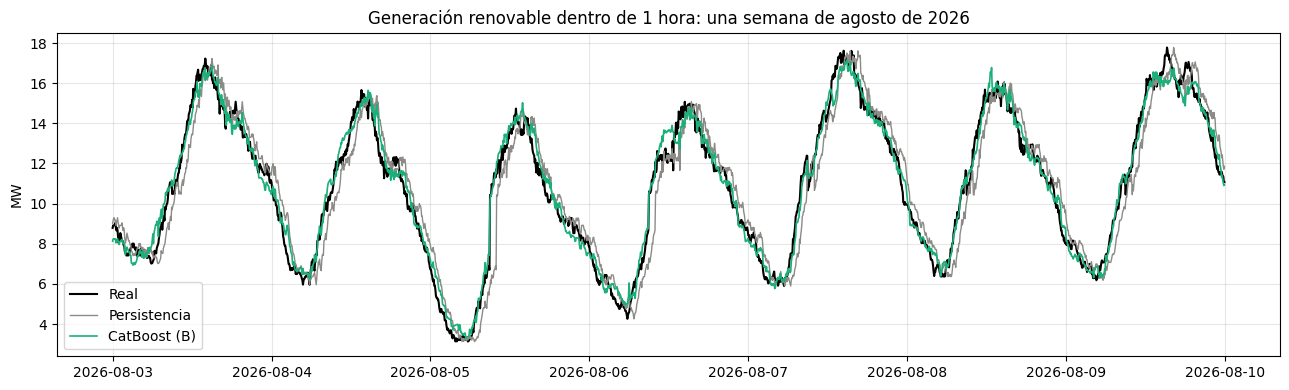

In [11]:
mejor = tabla.drop(index="Persistencia")["MAE (MW)"].idxmin()
print("Mejor modelo a 1 hora:", mejor)

semana = slice("2026-08-03", "2026-08-09")
comparacion = pd.DataFrame({
    "Real": test[OBJETIVO],
    "Persistencia": prediccion_persistencia,
    mejor: modelos[mejor][2],
}, index=test.index)

fig, eje = plt.subplots(figsize=(13, 4))
datos_semana = comparacion.loc[semana]
eje.plot(datos_semana.index, datos_semana["Real"], color="black", linewidth=1.5, label="Real")
eje.plot(datos_semana.index, datos_semana["Persistencia"], color="#8c8b87", linewidth=1, label="Persistencia")
eje.plot(datos_semana.index, datos_semana[mejor], color=VERDE, linewidth=1.2, label=mejor)
eje.set_ylabel("MW")
eje.set_title("Generación renovable dentro de 1 hora: una semana de agosto de 2026")
eje.legend()
eje.grid(alpha=0.3)
guardar(fig, "06_semana_real_vs_prediccion")

La persistencia va siempre "un paso por detrás": repite lo que pasó hace una hora, así que llega tarde a cada subida y a cada bajada. El modelo, en cambio, anticipa bastante bien la subida de la mañana y la bajada de la noche, porque ha aprendido el ciclo diario a partir de la hora y de la posición del sol. Donde más le cuesta es en los cambios bruscos de viento, que en los datos simulados son bastante aleatorios.

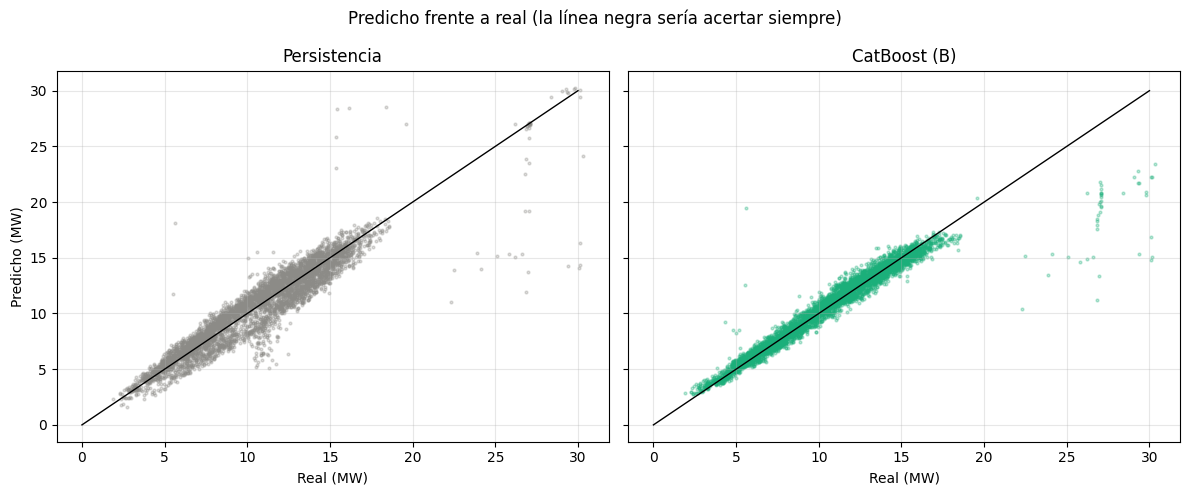

In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
muestra = comparacion.sample(5000, random_state=0)
for eje, nombre, color in [(ejes[0], "Persistencia", "#8c8b87"), (ejes[1], mejor, VERDE)]:
    eje.scatter(muestra["Real"], muestra[nombre], s=4, alpha=0.3, color=color)
    eje.plot([0, 30], [0, 30], color="black", linewidth=1)
    eje.set_xlabel("Real (MW)")
    eje.set_title(nombre)
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("Predicho (MW)")
fig.suptitle("Predicho frente a real (la línea negra sería acertar siempre)")
guardar(fig, "06_scatter_predicho_vs_real")

Los puntos del modelo están mucho más pegados a la diagonal que los de la persistencia. La excepción son los pocos momentos en los que la generación real supera los 20 MW: el modelo se queda corto y predice entre 15 y 22 MW. Son los episodios de viento muy fuerte, de los que hay muy pocos en el entrenamiento, así que el modelo casi no ha podido aprender de ellos.

### 6.3 ¿A qué hora se equivocan más?

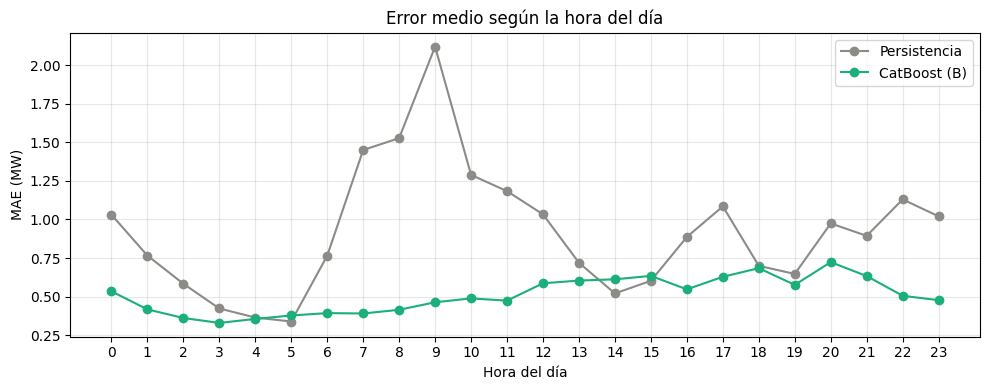

In [13]:
errores = comparacion.drop(columns="Real").sub(comparacion["Real"], axis=0).abs()
errores_hora = errores.groupby(errores.index.hour).mean()
errores_hora.round(3).to_csv(TABLAS / "06_error_por_hora.csv")

fig, eje = plt.subplots(figsize=(10, 4))
eje.plot(errores_hora.index, errores_hora["Persistencia"], color="#8c8b87", marker="o", label="Persistencia")
eje.plot(errores_hora.index, errores_hora[mejor], color=VERDE, marker="o", label=mejor)
eje.set_xticks(range(24))
eje.set_xlabel("Hora del día")
eje.set_ylabel("MAE (MW)")
eje.set_title("Error medio según la hora del día")
eje.legend()
eje.grid(alpha=0.3)
guardar(fig, "06_error_por_hora")

La persistencia falla sobre todo entre las 7 y las 10 de la mañana, con un pico de más de 2 MW a las 9, que es cuando sale el sol y la generación sube más rápido. También falla más al final de la tarde y por la noche, cuando baja el viento. El modelo mantiene el error casi constante durante todo el día, entre 0,35 y 0,7 MW, y es en esas horas de cambio donde está casi toda su ventaja.

No gana a todas horas: de 4 a 5 de la madrugada y de 14 a 15 h, cuando la generación apenas cambia, la persistencia se equivoca un poco menos que el modelo. Es normal, porque en esos momentos "lo mismo que ahora" es casi la respuesta exacta.

## 7. Qué variables pesan más

Los dos modelos permiten ver qué variables han usado más para decidir. Lo miramos con el conjunto A, que es el que no incluye la generación actual y por tanto da una imagen más clara de qué información útil hay en los datos.

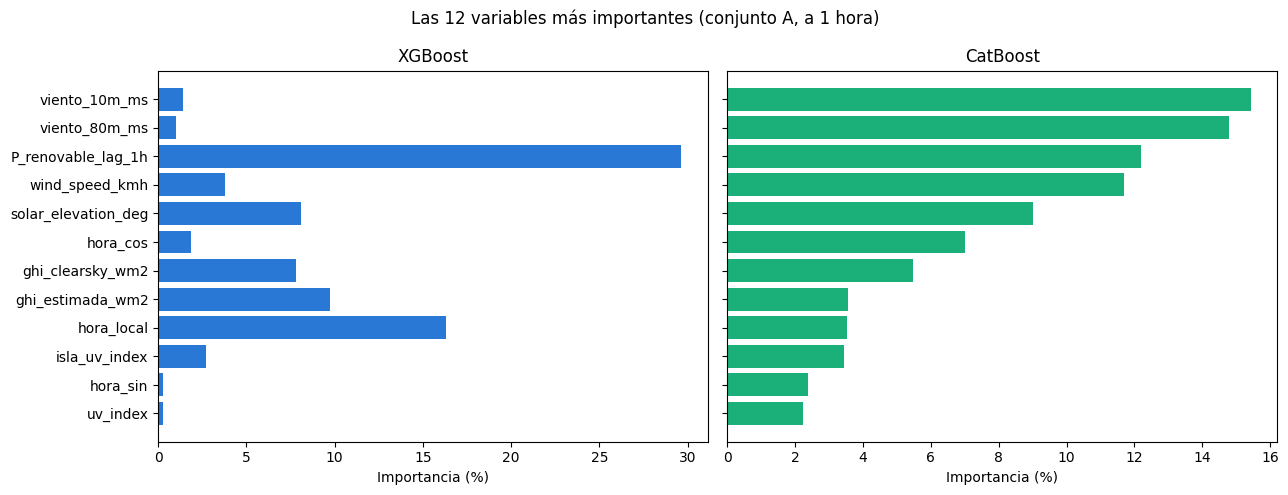

In [14]:
xgb_a, vars_a, _ = modelos["XGBoost (A)"]
cat_a, _, _ = modelos["CatBoost (A)"]

importancias = pd.DataFrame({
    "XGBoost": xgb_a.feature_importances_ / xgb_a.feature_importances_.sum() * 100,
    "CatBoost": cat_a.get_feature_importance() / cat_a.get_feature_importance().sum() * 100,
}, index=vars_a).round(2)
importancias = importancias.sort_values("CatBoost", ascending=False)
importancias.to_csv(TABLAS / "07_importancia_variables.csv")

top = importancias.head(12)[::-1]
fig, ejes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
ejes[0].barh(top.index, top["XGBoost"], color=AZUL)
ejes[0].set_title("XGBoost")
ejes[1].barh(top.index, top["CatBoost"], color=VERDE)
ejes[1].set_title("CatBoost")
for eje in ejes:
    eje.set_xlabel("Importancia (%)")
fig.suptitle("Las 12 variables más importantes (conjunto A, a 1 hora)")
guardar(fig, "07_importancia_variables")

Los dos modelos usan el mismo tipo de información, pero la reparten de forma distinta. XGBoost se apoya sobre todo en la generación de hace una hora (26 %) y en la hora del día (19 %), seguidas de la elevación del sol y la radiación. CatBoost reparte más el peso: lo que más usa es el viento, seguido de la generación de hace una hora y de la elevación del sol.

En CatBoost el viento aparece tres veces arriba (`viento_10m_ms`, `viento_80m_ms` y `wind_speed_kmh`), pero en realidad es la misma información en distintas unidades, así que el modelo se reparte la importancia entre las tres. XGBoost elige una y casi ignora las otras. Esto nos dice que podríamos quitar variables repetidas sin perder nada.

En conjunto coincide con lo que vimos en el EDA: la generación depende del viento y del ciclo diario y tiene mucha memoria a corto plazo. Las variables de calendario (festivos, día de la semana) tienen un peso muy pequeño, como esperábamos.

## 8. Predicción a 24 horas

Repetimos lo mismo con el otro target, la generación dentro de 24 horas, que es el que serviría para planificar el despacho del día siguiente. Aquí la persistencia es "dentro de 24 horas habrá lo mismo que ahora", es decir, lo mismo que a esta hora de hoy.

In [15]:
OBJETIVO_24 = "target_P_renovable_t+24h"
train24, val24, test24 = dividir(datos, OBJETIVO_24)

resultados_24 = [evaluar("Persistencia", test24[OBJETIVO_24], test24["P_renovable_MW"])]
for conjunto, variables in [("A", variables_A), ("B", variables_B)]:
    modelo = entrenar_xgboost(train24, val24, variables, OBJETIVO_24)
    resultados_24.append(evaluar(f"XGBoost ({conjunto})", test24[OBJETIVO_24], modelo.predict(test24[variables])))
    modelo = entrenar_catboost(train24, val24, variables, OBJETIVO_24)
    resultados_24.append(evaluar(f"CatBoost ({conjunto})", test24[OBJETIVO_24], modelo.predict(test24[variables])))

tabla_24 = pd.DataFrame(resultados_24).set_index("modelo")
tabla_24["mejora sobre la persistencia (%)"] = 100 * (1 - tabla_24["MAE (MW)"] / tabla_24.loc["Persistencia", "MAE (MW)"])
tabla_24 = tabla_24.round(3)
tabla_24.to_csv(TABLAS / "08_comparativa_24h.csv")
tabla_24

,MAE (MW),RMSE (MW),R²,mejora sobre la persistencia (%)
modelo,,,,
Persistencia,1.961,2.886,0.422,0.000
XGBoost (A),1.672,2.401,0.600,14.746
CatBoost (A),1.531,2.196,0.665,21.925
XGBoost (B),1.653,2.376,0.609,15.718
CatBoost (B),1.499,2.178,0.671,23.589


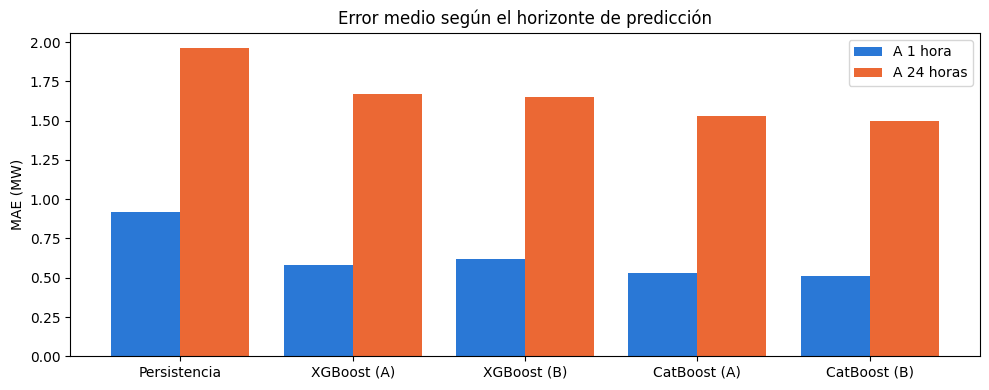

In [16]:
fig, eje = plt.subplots(figsize=(10, 4))
posiciones = np.arange(len(tabla.index))
eje.bar(posiciones - 0.2, tabla["MAE (MW)"], width=0.4, color=AZUL, label="A 1 hora")
eje.bar(posiciones + 0.2, tabla_24.loc[tabla.index, "MAE (MW)"], width=0.4, color=NARANJA, label="A 24 horas")
eje.set_xticks(posiciones, tabla.index)
eje.set_ylabel("MAE (MW)")
eje.set_title("Error medio según el horizonte de predicción")
eje.legend()
guardar(fig, "08_comparativa_horizontes")

A 24 horas todo es más difícil, como ya anticipaba la autocorrelación del EDA. La persistencia pasa a equivocarse unos 2 MW de media y los modelos, entre 1,5 y 1,8 MW. Siguen mejorando la referencia, pero mucho menos que a una hora: entre un 10 % y un 24 %. CatBoost vuelve a ser el mejor.

Tiene sentido: a una hora vista el viento actual dice mucho del que habrá; a un día vista solo nos queda el ciclo diario y poco más. Para mejorar aquí haría falta información del futuro, como una previsión meteorológica, que es justo lo que usan los operadores eléctricos reales.

In [17]:
# Guardamos los dos modelos de CatBoost a 1 hora para poder usarlos más adelante en el despacho
modelos["CatBoost (A)"][0].save_model(str(MODELOS / "catboost_1h_conjuntoA.cbm"))
modelos["CatBoost (B)"][0].save_model(str(MODELOS / "catboost_1h_conjuntoB.cbm"))
modelos["XGBoost (A)"][0].save_model(str(MODELOS / "xgboost_1h_conjuntoA.json"))
print("Modelos guardados en", MODELOS)

Modelos guardados en ..\resultados\05_modelos\modelos


## 9. Conclusiones y siguientes pasos

1. **Los dos modelos funcionan.** A 1 hora reducen el error de la persistencia entre un 34 % y un 45 %, y CatBoost es el mejor en todas las pruebas, con un error medio de unos 0,5 MW y un R² cercano a 0,94.
2. **La ventaja está en los cambios rápidos.** Los modelos anticipan las subidas y bajadas del ciclo diario, que es donde la persistencia más falla. Donde peor van es en los picos de viento muy fuerte, de los que hay pocos ejemplos.
3. **La generación actual apenas aporta** si el modelo ya tiene el viento actual y la generación de hace una hora. Podemos usar cualquiera de los dos conjuntos; el B es ligeramente mejor con CatBoost.
4. **A 24 horas la mejora es mucho menor**, porque sin una previsión meteorológica el modelo no tiene forma de saber qué viento habrá mañana.
5. **Los modelos paran pronto** (entre 60 y 180 árboles), lo que indica que no hay mucho más que sacar de estos datos sin añadir información nueva.

Siguientes pasos que proponemos:

- Quitar las variables repetidas (el mismo viento en distintas unidades).
- Ajustar los hiperparámetros con validación cruzada temporal (`TimeSeriesSplit`) en lugar de una sola validación.
- Elegir los retardos con el algoritmo de retardos (correlación cruzada) en vez de los que pusimos a mano.
- Probar a entrenar con el viento real de Open-Meteo, que tiene la estacionalidad que le falta al simulado.
- Usar el modelo elegido en el algoritmo de despacho.